# MOBA Early-Game Diagnostics & Win Probability

**基于 League of Legends 高段位排位赛的 10 分钟战局分析** | Cao Siyuan

## 1. 研究问题与分析边界

面向游戏数据分析、战局复盘与胜率展示场景，本项目研究：

1. 10 分钟的经济差距在多大程度上转化为最终胜利？不同优势程度下，逆风翻盘仍有多大可能？
2. 当经济差相近时，史诗资源控制是否提供额外的战局诊断信息？
3. 相对于仅使用经济差的简单模型，战斗、资源、视野等多维信息能否提高样本外胜率预测的质量？
4. 模型给出的概率在多大程度上可信，哪些局势适合更有把握地展示预测，哪些需要保留不确定性？

**边界：** 一行是一场比赛的第 10 分钟累计状态，目标是比赛最终胜负。我们估计的是观察性关联、条件胜率与预测能力，不是控龙、拿一血等操作的因果效应。数据没有事件时间序列、处理前协变量、英雄阵容、选手实力、版本或后续操作，无法识别可靠的干预效应。

## 2. 环境、数据与质量检查

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.stats import norm
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, brier_score_loss,
    f1_score, log_loss, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
TEST_SIZE = 0.25
BOOTSTRAP_N = 1000
ROOT = Path.cwd()
DATA_PATH = ROOT / "high_diamond_ranked_10min.csv"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid", palette="colorblind")


def save_table(table, filename):
    table.to_csv(TABLES / filename, index=False)
    return table


def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


raw = pd.read_csv(DATA_PATH)
display(raw.head(5))

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,...,redDeaths,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,0,0,17210,6.6000,17039,...,9,8,0,0,0,0,16567,6.8000,17047,197,55,-643,8,19.7000,1656.7000
1,4523371949,0,12,1,0,5,5,5,0,0,0,0,14712,6.6000,16265,...,5,2,2,1,1,1,17620,6.8000,17438,240,52,2908,1173,24.0000,1762.0000
2,4521474530,0,15,0,0,7,11,4,1,1,0,0,16113,6.4000,16221,...,7,14,0,0,0,0,17285,6.8000,17254,203,28,1172,1033,20.3000,1728.5000
3,4524384067,0,43,1,0,4,5,5,1,0,1,0,15157,7.0000,17954,...,4,10,0,0,0,0,16478,7.0000,17961,235,47,1321,7,23.5000,1647.8000
4,4436033771,0,75,4,0,6,6,6,0,0,0,0,16400,7.0000,18543,...,6,7,1,1,0,0,17404,7.0000,18313,225,67,1004,-230,22.5000,1740.4000


In [2]:
def check_equal(left, right):
    return bool(np.allclose(left, right, rtol=0, atol=1e-8))


audit = pd.DataFrame([
    ("Matches", len(raw), "rows"),
    ("Original columns", raw.shape[1], "columns"),
    ("Unique game IDs", raw["gameId"].nunique(), "underlying matches"),
    ("Missing cells", int(raw.isna().sum().sum()), "expected 0"),
    ("Duplicate rows", int(raw.duplicated().sum()), "expected 0"),
    ("Duplicate game IDs", int(raw["gameId"].duplicated().sum()), "expected 0"),
    ("Blue wins", int(raw["blueWins"].sum()), "target count"),
    ("Blue win rate", raw["blueWins"].mean(), "target prevalence"),
], columns=["check", "value", "interpretation"])

identity_checks = pd.DataFrame([
    ("Blue gold difference", check_equal(raw["blueGoldDiff"], raw["blueTotalGold"] - raw["redTotalGold"])),
    ("Red gold difference is the opposite", check_equal(raw["blueGoldDiff"], -raw["redGoldDiff"])),
    ("Blue experience difference", check_equal(raw["blueExperienceDiff"], raw["blueTotalExperience"] - raw["redTotalExperience"])),
    ("Red experience difference is the opposite", check_equal(raw["blueExperienceDiff"], -raw["redExperienceDiff"])),
    ("Blue kills = red deaths", check_equal(raw["blueKills"], raw["redDeaths"])),
    ("Red kills = blue deaths", check_equal(raw["redKills"], raw["blueDeaths"])),
    ("Exactly one first-blood side", check_equal(raw["blueFirstBlood"] + raw["redFirstBlood"], np.ones(len(raw)))),
    ("Blue elite monsters = dragons + heralds", check_equal(raw["blueEliteMonsters"], raw["blueDragons"] + raw["blueHeralds"])),
    ("Red elite monsters = dragons + heralds", check_equal(raw["redEliteMonsters"], raw["redDragons"] + raw["redHeralds"])),
    ("Blue gold/min = total gold / 10", check_equal(raw["blueGoldPerMin"], raw["blueTotalGold"] / 10)),
    ("Red gold/min = total gold / 10", check_equal(raw["redGoldPerMin"], raw["redTotalGold"] / 10)),
    ("Blue CS/min = lane CS / 10", check_equal(raw["blueCSPerMin"], raw["blueTotalMinionsKilled"] / 10)),
    ("Red CS/min = lane CS / 10", check_equal(raw["redCSPerMin"], raw["redTotalMinionsKilled"] / 10)),
], columns=["identity", "verified"])

assert raw["gameId"].is_unique
assert raw.isna().sum().sum() == 0
assert set(raw["blueWins"].unique()) == {0, 1}
assert identity_checks["verified"].all()

display(save_table(audit, "data_quality.csv"))
display(save_table(identity_checks, "feature_identity_checks.csv"))

,check,value,interpretation
0,Matches,9879.0000,rows
1,Original columns,40.0000,columns
2,Unique game IDs,9879.0000,underlying matches
3,Missing cells,0.0000,expected 0
4,Duplicate rows,0.0000,expected 0
5,Duplicate game IDs,0.0000,expected 0
6,Blue wins,4930.0000,target count
7,Blue win rate,0.4990,target prevalence


,identity,verified
0,Blue gold difference,True
1,Red gold difference is the opposite,True
2,Blue experience difference,True
3,Red experience difference is the opposite,True
4,Blue kills = red deaths,True
5,Red kills = blue deaths,True
6,Exactly one first-blood side,True
7,Blue elite monsters = dragons + heralds,True
8,Red elite monsters = dragons + heralds,True
9,Blue gold/min = total gold / 10,True


## 3. 战局指标体系与特征工程

将每场比赛保持为一个独立观测。对具有两方对应关系的指标，构造蓝方减红方的差值（正数表示蓝方领先）；一血使用原始蓝方标记。经济、成长、战斗、地图资源和视野构成清晰的指标维度。

不使用比赛 ID、双方镜像字段、每分钟与累计值的重复形式；不重复累加史诗资源，也不以全样本胜负相关性筛选模型特征。

In [3]:
features = pd.DataFrame({
    "game_id": raw["gameId"],
    "blue_win": raw["blueWins"],
    "gold_diff": raw["blueGoldDiff"],
    "xp_diff": raw["blueExperienceDiff"],
    "kill_diff": raw["blueKills"] - raw["redKills"],
    "assist_diff": raw["blueAssists"] - raw["redAssists"],
    "first_blood": raw["blueFirstBlood"],
    "lane_cs_diff": raw["blueTotalMinionsKilled"] - raw["redTotalMinionsKilled"],
    "jungle_cs_diff": raw["blueTotalJungleMinionsKilled"] - raw["redTotalJungleMinionsKilled"],
    "dragon_diff": raw["blueDragons"] - raw["redDragons"],
    "herald_diff": raw["blueHeralds"] - raw["redHeralds"],
    "tower_diff": raw["blueTowersDestroyed"] - raw["redTowersDestroyed"],
    "wards_placed_diff": raw["blueWardsPlaced"] - raw["redWardsPlaced"],
    "wards_destroyed_diff": raw["blueWardsDestroyed"] - raw["redWardsDestroyed"],
})

# Epic resources are used as a composite diagnostic indicator, not an extra model feature.
features["epic_diff"] = features["dragon_diff"] + features["herald_diff"]
features["abs_gold_diff"] = features["gold_diff"].abs()

FEATURE_GROUPS = {
    "Economy & growth": ["gold_diff", "xp_diff"],
    "Combat": ["kill_diff", "assist_diff", "first_blood"],
    "Resource collection": ["lane_cs_diff", "jungle_cs_diff"],
    "Map objectives": ["dragon_diff", "herald_diff", "tower_diff"],
    "Vision": ["wards_placed_diff", "wards_destroyed_diff"],
}
MODEL_FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

feature_dictionary = pd.DataFrame([
    (group, feature, "Blue minus Red" if feature != "first_blood" else "Blue = 1")
    for group, group_features in FEATURE_GROUPS.items()
    for feature in group_features
], columns=["domain", "feature", "definition"])

display(save_table(feature_dictionary, "feature_dictionary.csv"))
print(f"{len(MODEL_FEATURES)} model features across {len(FEATURE_GROUPS)} domains.")

,domain,feature,definition
0,Economy & growth,gold_diff,Blue minus Red
1,Economy & growth,xp_diff,Blue minus Red
2,Combat,kill_diff,Blue minus Red
3,Combat,assist_diff,Blue minus Red
4,Combat,first_blood,Blue = 1
5,Resource collection,lane_cs_diff,Blue minus Red
6,Resource collection,jungle_cs_diff,Blue minus Red
7,Map objectives,dragon_diff,Blue minus Red
8,Map objectives,herald_diff,Blue minus Red
9,Map objectives,tower_diff,Blue minus Red


12 model features across 5 domains.


,feature,mean_blue_wins,mean_blue_losses,standardized_mean_difference,correlation_with_win,absolute_smd
0,gold_diff,1270.7181,-1237.0667,1.1892,0.5111,1.1892
1,xp_diff,908.2744,-971.8990,1.1228,0.4896,1.1228
2,kill_diff,2.0613,-1.9610,1.0924,0.4794,1.0924
3,assist_diff,2.2124,-2.2378,0.8364,0.3859,0.8364
5,lane_cs_diff,8.9335,-10.1960,0.6500,0.3091,0.6500
7,dragon_diff,0.1552,-0.2566,0.4819,0.2343,0.4819
4,first_blood,0.6059,0.4041,0.4120,0.2018,0.4120
6,jungle_cs_diff,1.6152,-3.2128,0.3431,0.1691,0.3431
9,tower_diff,0.0592,-0.0422,0.3162,0.1562,0.3162
8,herald_diff,0.0998,-0.0436,0.2452,0.1217,0.2452


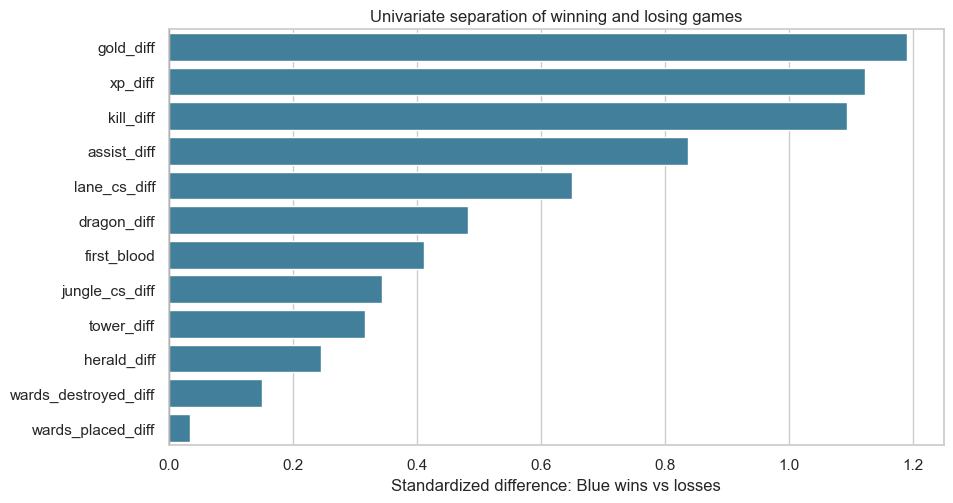

In [4]:
univariate_rows = []
for name in MODEL_FEATURES:
    winners = features.loc[features["blue_win"] == 1, name]
    losers = features.loc[features["blue_win"] == 0, name]
    pooled_sd = np.sqrt(
        ((len(winners) - 1) * winners.var() + (len(losers) - 1) * losers.var())
        / (len(winners) + len(losers) - 2)
    )
    smd = (winners.mean() - losers.mean()) / pooled_sd if pooled_sd else np.nan
    univariate_rows.append({
        "feature": name,
        "mean_blue_wins": winners.mean(),
        "mean_blue_losses": losers.mean(),
        "standardized_mean_difference": smd,
        "correlation_with_win": features[name].corr(features["blue_win"]),
    })

univariate_summary = pd.DataFrame(univariate_rows)
univariate_summary["absolute_smd"] = univariate_summary["standardized_mean_difference"].abs()
univariate_summary = univariate_summary.sort_values("absolute_smd", ascending=False)
display(save_table(univariate_summary, "univariate_signal_summary.csv"))

fig, ax = plt.subplots(figsize=(10, 5.4))
sns.barplot(
    data=univariate_summary,
    x="standardized_mean_difference", y="feature",
    color="#3485A8", ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Standardized difference: Blue wins vs losses", ylabel="", title="Univariate separation of winning and losing games")
save_figure(fig, "univariate_signal_strength.png")

## 4. 核心战局分析：经济优势的胜利转化与翻盘风险（Pandas + 统计区间）

以下从 **经济领先方** 的角度统计，而不是只研究蓝方；经济完全持平的比赛不定义领先方并单独计数。

经济差阈值按实务解释性划分为 0–500、500–1,500、1,500–3,000、3,000+。这些区间不是通过胜率反向搜索得到的最优阈值。每组同时报告比赛数、胜率、翻盘比例和 Wilson 95% 置信区间，避免仅看点估计。

In [5]:
def wilson_interval(successes, totals, alpha=0.05):
    """Wilson interval for a binomial proportion."""
    successes = np.asarray(successes, dtype=float)
    totals = np.asarray(totals, dtype=float)
    z = norm.ppf(1 - alpha / 2)
    p = successes / totals
    denominator = 1 + z**2 / totals
    center = (p + z**2 / (2 * totals)) / denominator
    half = z * np.sqrt(p * (1 - p) / totals + z**2 / (4 * totals**2)) / denominator
    return np.maximum(0, center - half), np.minimum(1, center + half)


def add_win_rate_and_ci(table, successes="wins", totals="n"):
    table = table.copy()
    table["win_rate"] = table[successes] / table[totals]
    table["ci_low"], table["ci_high"] = wilson_interval(table[successes], table[totals])
    return table


# Orient each game to the team leading in gold at minute 10.
leader_state = features.loc[
    features["gold_diff"].ne(0),
    ["game_id", "gold_diff", "blue_win", "epic_diff"],
].copy()
blue_leads = leader_state["gold_diff"].gt(0)
leader_state["gold_gap"] = leader_state["gold_diff"].abs()
leader_state["leader_won"] = np.where(
    blue_leads, leader_state["blue_win"], 1 - leader_state["blue_win"]
)
leader_state["leader_epic_diff"] = np.where(
    blue_leads, leader_state["epic_diff"], -leader_state["epic_diff"]
)

GOLD_BAND_EDGES = [0, 500, 1500, 3000, np.inf]
GOLD_BAND_LABELS = ["0-500", "500-1500", "1500-3000", "3000+"]
leader_state["gold_band"] = pd.cut(
    leader_state["gold_gap"],
    bins=GOLD_BAND_EDGES,
    labels=GOLD_BAND_LABELS,
    right=True,
)
assert leader_state["gold_band"].notna().all()

economy_counts = (
    leader_state.groupby("gold_band", observed=True, as_index=False)
    .agg(n=("leader_won", "size"), wins=("leader_won", "sum"))
)
economy_counts.insert(0, "band_order", economy_counts["gold_band"].cat.codes + 1)
economy_summary = add_win_rate_and_ci(economy_counts)
economy_summary["comeback_rate"] = 1 - economy_summary["win_rate"]
equal_gold = int(features["gold_diff"].eq(0).sum())

assert economy_summary["n"].sum() + equal_gold == len(features)
display(save_table(economy_summary, "economy_lead_conversion.csv"))
print(f"Exact economic ties (excluded from the leader view): {equal_gold}")

,band_order,gold_band,n,wins,win_rate,ci_low,ci_high,comeback_rate
0,1,0-500,1682,884,0.5256,0.5017,0.5493,0.4744
1,2,500-1500,3021,1928,0.6382,0.6209,0.6551,0.3618
2,3,1500-3000,3082,2429,0.7881,0.7733,0.8022,0.2119
3,4,3000+,2092,1899,0.9077,0.8946,0.9194,0.0923


Exact economic ties (excluded from the leader view): 2


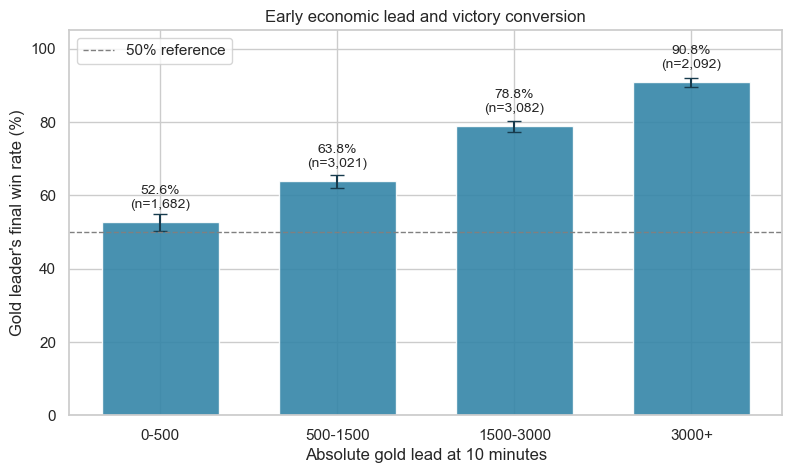

In [6]:
fig, ax = plt.subplots(figsize=(9.2, 5.0))
positions = np.arange(len(economy_summary))
rate = economy_summary["win_rate"].to_numpy()
errors = np.vstack([
    rate - economy_summary["ci_low"].to_numpy(),
    economy_summary["ci_high"].to_numpy() - rate,
])

ax.bar(positions, rate * 100, color="#3485A8", width=0.66, alpha=0.9)
ax.errorbar(positions, rate * 100, yerr=errors * 100, fmt="none", color="#173B4D", capsize=5)
for i, row in economy_summary.iterrows():
    ax.text(i, row["win_rate"] * 100 + 4, f"{row['win_rate']:.1%}\n(n={row['n']:,})", ha="center", fontsize=10)
ax.axhline(50, linestyle="--", color="gray", linewidth=1, label="50% reference")
ax.set(
    xticks=positions, xticklabels=economy_summary["gold_band"],
    ylim=(0, 105), xlabel="Absolute gold lead at 10 minutes",
    ylabel="Gold leader's final win rate (%)", title="Early economic lead and victory conversion",
)
ax.legend(loc="upper left")
save_figure(fig, "economy_lead_conversion.png")

## 5. 同一经济背景下的地图资源诊断

仅比较全样本资源领先和落后容易把不同经济背景混在一起。因此，在上述经济差区间内，进一步按经济领先方是否同时领先、持平或落后于对手的史诗资源数进行交叉分层。资源状态依据原始计数差定义，零是持平，而不是标准化后的零。

这类条件关联可用于复盘时识别经济与地图控制不一致的局势，但分层内仍可能存在剩余经济差和未观测混杂，不能解释为拿龙或先锋的因果贡献。

In [7]:
OBJECTIVE_STATES = ["Trailing", "Even", "Leading"]
leader_state["objective_state"] = pd.Categorical(
    np.select(
        [leader_state["leader_epic_diff"] < 0, leader_state["leader_epic_diff"] == 0],
        OBJECTIVE_STATES[:2],
        default=OBJECTIVE_STATES[2],
    ),
    categories=OBJECTIVE_STATES,
    ordered=True,
)

objective_counts = (
    leader_state.groupby(["gold_band", "objective_state"], observed=True, as_index=False)
    .agg(n=("leader_won", "size"), wins=("leader_won", "sum"))
)
objective_counts.insert(0, "band_order", objective_counts["gold_band"].cat.codes + 1)
objective_counts.insert(2, "objective_order", objective_counts["objective_state"].cat.codes + 1)
objective_summary = add_win_rate_and_ci(objective_counts)
assert objective_summary["n"].sum() == economy_summary["n"].sum()
display(save_table(objective_summary, "gold_objective_context.csv"))

# A separate raw-unit check prevents a zero objective gap from being mislabeled as a lead.
relative_objective = (
    features.assign(
        objective_state=np.select(
            [features["epic_diff"] < 0, features["epic_diff"] == 0],
            OBJECTIVE_STATES[:2],
            default=OBJECTIVE_STATES[2],
        )
    )
    .groupby("objective_state", as_index=False)
    .agg(n=("blue_win", "size"), wins=("blue_win", "sum"))
)
relative_objective = add_win_rate_and_ci(relative_objective)
display(save_table(relative_objective, "blue_objective_state.csv"))

,band_order,gold_band,objective_order,objective_state,n,wins,win_rate,ci_low,ci_high
0,1,0-500,1,Trailing,572,251,0.4388,0.3987,0.4798
1,1,0-500,2,Even,526,282,0.5361,0.4934,0.5783
2,1,0-500,3,Leading,584,351,0.6010,0.5608,0.6400
3,2,500-1500,1,Trailing,867,504,0.5813,0.5482,0.6137
4,2,500-1500,2,Even,929,565,0.6082,0.5764,0.6391
5,2,500-1500,3,Leading,1225,859,0.7012,0.6750,0.7262
6,3,1500-3000,1,Trailing,681,490,0.7195,0.6846,0.7520
7,3,1500-3000,2,Even,917,705,0.7688,0.7404,0.7949
8,3,1500-3000,3,Leading,1484,1234,0.8315,0.8116,0.8497
9,4,3000+,1,Trailing,291,248,0.8522,0.8069,0.8884


,objective_state,n,wins,win_rate,ci_low,ci_high
0,Even,2928,1466,0.5007,0.4826,0.5188
1,Leading,3371,2204,0.6538,0.6376,0.6697
2,Trailing,3580,1260,0.3520,0.3365,0.3678


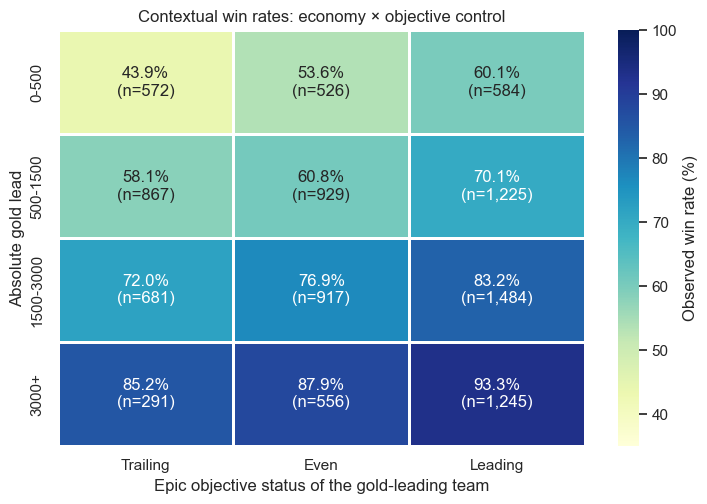

In [8]:
band_labels = economy_summary["gold_band"].tolist()
state_labels = ["Trailing", "Even", "Leading"]

rate_matrix = objective_summary.pivot(index="gold_band", columns="objective_state", values="win_rate")
n_matrix = objective_summary.pivot(index="gold_band", columns="objective_state", values="n")
rate_matrix = rate_matrix.reindex(index=band_labels, columns=state_labels)
n_matrix = n_matrix.reindex(index=band_labels, columns=state_labels)

annotations = np.empty(rate_matrix.shape, dtype=object)
for i in range(rate_matrix.shape[0]):
    for j in range(rate_matrix.shape[1]):
        p, n = rate_matrix.iloc[i, j], n_matrix.iloc[i, j]
        annotations[i, j] = f"{p:.1%}\n(n={int(n):,})" if pd.notna(p) else ""

fig, ax = plt.subplots(figsize=(8.5, 5.4))
sns.heatmap(
    rate_matrix * 100, annot=annotations, fmt="", cmap="YlGnBu",
    vmin=35, vmax=100, linewidths=1.0,
    cbar_kws={"label": "Observed win rate (%)"}, ax=ax,
)
ax.set(
    xlabel="Epic objective status of the gold-leading team",
    ylabel="Absolute gold lead",
    title="Contextual win rates: economy × objective control",
)
save_figure(fig, "gold_objective_context.png")

## 6. 样本外胜率预测：信息增量，而不只是模型准确率

使用固定的分层 75% / 25% 训练与测试划分。训练集中进行 5 折交叉验证，按 log loss 选择超参数；随后在同一未参与训练或调参的测试集上报告：

- **先验基线：** 只使用训练集胜率；
- **Gold LR：** 只使用 10 分钟经济差；
- **Gold + XP LR：** 检查经验差的增量价值；
- **Full LR：** 使用五类战局信号的逻辑回归；
- **Full RF：** 检查非线性随机森林是否提供额外预测能力。

概率模型用于胜率展示，因此除 AUC、Accuracy 外，还关注 log loss、Brier score 与校准情况。标准化仅在训练折内部拟合。

In [9]:
train_idx, test_idx = train_test_split(
    features.index.to_numpy(),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=features["blue_win"],
)
y_train = features.loc[train_idx, "blue_win"]
y_test = features.loc[test_idx, "blue_win"]
assert set(train_idx).isdisjoint(test_idx)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "log_loss": "neg_log_loss",
    "auc": "roc_auc",
    "brier": "neg_brier_score",
}


def lr_pipeline():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED),
    )


lr_grid = {"logisticregression__C": [0.03, 0.1, 1.0, 10.0]}
model_specs = {
    "Prior baseline": (["gold_diff"], DummyClassifier(strategy="prior"), {}),
    "Gold LR": (["gold_diff"], lr_pipeline(), lr_grid),
    "Gold + XP LR": (["gold_diff", "xp_diff"], lr_pipeline(), lr_grid),
    "Full LR": (MODEL_FEATURES, lr_pipeline(), lr_grid),
    "Full RF": (
        MODEL_FEATURES,
        RandomForestClassifier(n_estimators=180, random_state=SEED, n_jobs=1),
        {"max_depth": [6, 10], "min_samples_leaf": [10, 30]},
    ),
}

best_estimators = {}
probabilities = {}
cv_rows = []

for name, (columns, estimator, grid) in model_specs.items():
    search = GridSearchCV(
        estimator, grid, scoring=scoring, refit="log_loss",
        cv=cv, n_jobs=1, error_score="raise",
    )
    search.fit(features.loc[train_idx, columns], y_train)
    best_estimators[name] = search.best_estimator_
    probabilities[name] = search.predict_proba(features.loc[test_idx, columns])[:, 1]
    best_i = search.best_index_
    cv_rows.append({
        "model": name,
        "n_features": 0 if name == "Prior baseline" else len(columns),
        "cv_log_loss_mean": -search.cv_results_["mean_test_log_loss"][best_i],
        "cv_log_loss_sd": search.cv_results_["std_test_log_loss"][best_i],
        "cv_auc_mean": search.cv_results_["mean_test_auc"][best_i],
        "cv_brier_mean": -search.cv_results_["mean_test_brier"][best_i],
        "best_params": str(search.best_params_),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("cv_log_loss_mean")
selected_model = cv_results.iloc[0]["model"]
print(f"Train: {len(train_idx):,} | Holdout: {len(test_idx):,}")
print(f"Selected by train-only cross-validated log loss: {selected_model}")
display(save_table(cv_results, "cross_validation_results.csv"))

Train: 7,409 | Holdout: 2,470
Selected by train-only cross-validated log loss: Full LR


,model,n_features,cv_log_loss_mean,cv_log_loss_sd,cv_auc_mean,cv_brier_mean,best_params
3,Full LR,12,0.5299,0.0042,0.8100,0.1778,{'logisticregression__C': 1.0}
4,Full RF,12,0.5354,0.0047,0.8071,0.1795,"{'max_depth': 6, 'min_samples_leaf': 30}"
2,Gold + XP LR,2,0.5363,0.0051,0.8049,0.1802,{'logisticregression__C': 0.1}
1,Gold LR,1,0.5395,0.0074,0.8016,0.1816,{'logisticregression__C': 10.0}
0,Prior baseline,0,0.6931,0.0000,0.5000,0.2500,{}


In [10]:
def expected_calibration_error(y, prob, n_bins=10):
    """Weighted empirical calibration gap over equal-width probability bins."""
    y = np.asarray(y)
    prob = np.asarray(prob)
    bin_id = np.clip(np.digitize(prob, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    error = 0.0
    for b in range(n_bins):
        mask = bin_id == b
        if mask.any():
            error += mask.mean() * abs(y[mask].mean() - prob[mask].mean())
    return error


def evaluate_probability(y, prob):
    pred = (prob >= 0.5).astype(int)
    return {
        "auc": roc_auc_score(y, prob),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "f1": f1_score(y, pred),
        "log_loss": log_loss(y, prob),
        "brier": brier_score_loss(y, prob),
        "ece_10_bins": expected_calibration_error(y, prob),
    }


holdout_metrics = pd.DataFrame([
    {"model": name, **evaluate_probability(y_test, prob)}
    for name, prob in probabilities.items()
])
holdout_metrics = holdout_metrics.merge(cv_results[["model", "cv_log_loss_mean"]], on="model")
holdout_metrics = holdout_metrics.sort_values("cv_log_loss_mean")
display(save_table(holdout_metrics, "holdout_model_metrics.csv"))

prediction_export = features.loc[test_idx, ["game_id", "blue_win", "gold_diff", "epic_diff", "xp_diff"]].copy()
for name, prob in probabilities.items():
    prediction_export[name] = prob
save_table(prediction_export, "holdout_predictions.csv")

,model,auc,accuracy,balanced_accuracy,f1,log_loss,brier,ece_10_bins,cv_log_loss_mean
3,Full LR,0.8108,0.7219,0.7219,0.7220,0.5268,0.1775,0.0220,0.5299
4,Full RF,0.8082,0.7194,0.7194,0.7195,0.5312,0.1790,0.0278,0.5354
2,Gold + XP LR,0.8049,0.7186,0.7186,0.7171,0.5340,0.1801,0.0151,0.5363
1,Gold LR,0.8010,0.7194,0.7194,0.7168,0.5385,0.1818,0.0150,0.5395
0,Prior baseline,0.5000,0.5008,0.5000,0.0000,0.6931,0.2500,0.0002,0.6931


,game_id,blue_win,gold_diff,epic_diff,xp_diff,Prior baseline,Gold LR,Gold + XP LR,Full LR,Full RF
6346,4473134497,0,-4962,0,-2384,0.4990,0.0501,0.0653,0.0604,0.0863
8339,4527186536,0,159,0,-369,0.4990,0.5214,0.4959,0.5805,0.5328
7836,4501534072,0,-125,-1,-637,0.4990,0.4795,0.4500,0.3804,0.4886
8321,4527527464,1,2402,1,2330,0.4990,0.8041,0.8289,0.8031,0.8394
9781,4496641163,0,-905,-2,-2229,0.4990,0.3674,0.2865,0.2210,0.2439
...,...,...,...,...,...,...,...,...,...,...
8654,4526187847,0,-3770,0,-2959,0.4990,0.0965,0.0914,0.0968,0.0967
1918,4496878235,0,-2564,0,-2920,0.4990,0.1789,0.1445,0.1590,0.1450
6536,4459959828,1,-277,0,-123,0.4990,0.4571,0.4647,0.4944,0.4756
7363,4465308301,0,-10830,0,-9333,0.4990,0.0016,0.0011,0.0019,0.0599


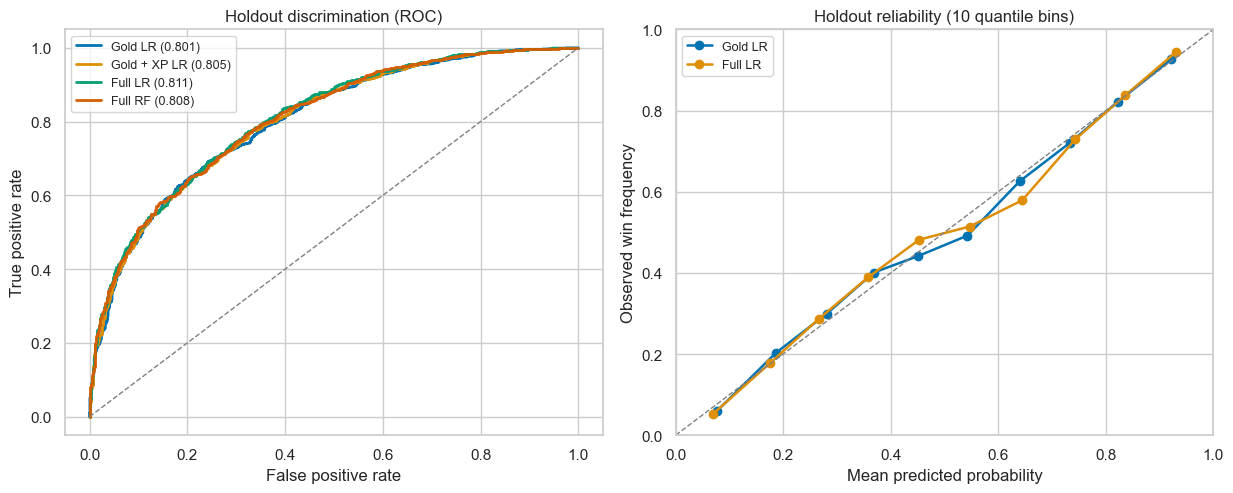

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
for name, prob in probabilities.items():
    if name == "Prior baseline":
        continue
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} ({auc:.3f})", linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Holdout discrimination (ROC)")
axes[0].legend(fontsize=9)

calibration_names = list(dict.fromkeys(["Gold LR", "Full LR", selected_model]))
for name in calibration_names:
    observed, predicted = calibration_curve(
        y_test, probabilities[name], n_bins=10, strategy="quantile"
    )
    axes[1].plot(predicted, observed, marker="o", linewidth=1.8, label=name)
axes[1].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[1].set(
    xlabel="Mean predicted probability", ylabel="Observed win frequency",
    title="Holdout reliability (10 quantile bins)", xlim=(0, 1), ylim=(0, 1),
)
axes[1].legend(fontsize=9)
fig.tight_layout()
save_figure(fig, "model_discrimination_calibration.png")

## 7. 多维信息的增量价值：配对 Bootstrap 与模块消融

要判断全量模型是否真的提供额外信息，比较同一局比赛上 Full LR 和 Gold LR 的预测结果，而不是将两组准确率视为彼此独立。对测试集比赛进行成对重采样，计算增量指标的经验 95% 区间；然后用特征模块消融探索各类信息的预测贡献。

In [12]:
def improvement(y, baseline, richer):
    """Positive differences favor the richer model."""
    return np.array([
        roc_auc_score(y, richer) - roc_auc_score(y, baseline),
        brier_score_loss(y, baseline) - brier_score_loss(y, richer),
        log_loss(y, baseline) - log_loss(y, richer),
        accuracy_score(y, richer >= 0.5) - accuracy_score(y, baseline >= 0.5),
    ])


y_array = y_test.to_numpy()
gold_prob = probabilities["Gold LR"]
full_prob = probabilities["Full LR"]
point = improvement(y_array, gold_prob, full_prob)
rng = np.random.default_rng(SEED)
replicates = []

for _ in range(BOOTSTRAP_N):
    resample = rng.integers(0, len(y_array), size=len(y_array))
    if len(np.unique(y_array[resample])) == 2:
        replicates.append(improvement(y_array[resample], gold_prob[resample], full_prob[resample]))

replicates = np.asarray(replicates)
comparison = pd.DataFrame({
    "metric": ["AUC gain", "Brier reduction", "Log loss reduction", "Accuracy gain"],
    "estimate": point,
    "ci_low": np.quantile(replicates, 0.025, axis=0),
    "ci_high": np.quantile(replicates, 0.975, axis=0),
})
display(save_table(comparison, "paired_bootstrap_increment.csv"))

,metric,estimate,ci_low,ci_high
0,AUC gain,0.0098,0.0049,0.0149
1,Brier reduction,0.0043,0.0020,0.0066
2,Log loss reduction,0.0117,0.0063,0.0174
3,Accuracy gain,0.0024,-0.0085,0.0138


,removed_domain,removed_features,auc_without_domain,auc_loss,log_loss_increase,brier_increase
0,Economy & growth,"gold_diff, xp_diff",0.8026,0.0082,0.0092,0.0037
3,Map objectives,"dragon_diff, herald_diff, tower_diff",0.8061,0.0048,0.0058,0.0021
2,Resource collection,"lane_cs_diff, jungle_cs_diff",0.8106,0.0002,0.0004,0.0001
1,Combat,"kill_diff, assist_diff, first_blood",0.8106,0.0002,0.0001,0.0001
4,Vision,"wards_placed_diff, wards_destroyed_diff",0.8110,-0.0002,-0.0002,-0.0001


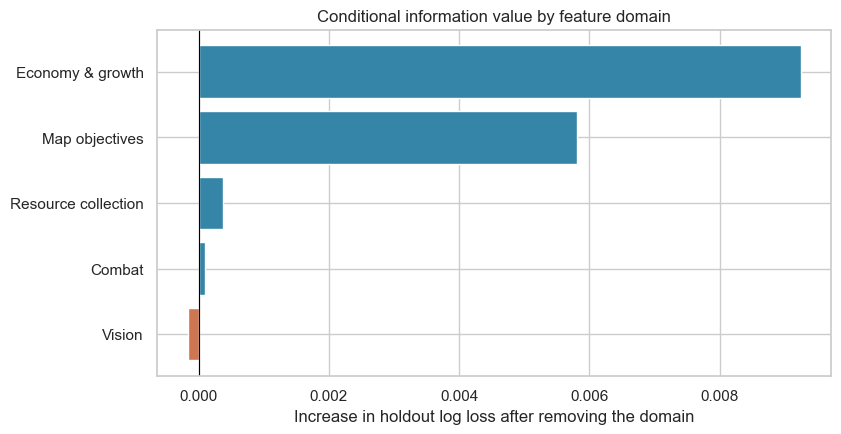

In [13]:
full_model = best_estimators["Full LR"]
full_metrics = evaluate_probability(y_test, full_prob)
ablation_rows = []

for group, removed in FEATURE_GROUPS.items():
    retained = [f for f in MODEL_FEATURES if f not in removed]
    reduced_model = clone(full_model)
    reduced_model.fit(features.loc[train_idx, retained], y_train)
    reduced_prob = reduced_model.predict_proba(features.loc[test_idx, retained])[:, 1]
    reduced_metrics = evaluate_probability(y_test, reduced_prob)
    ablation_rows.append({
        "removed_domain": group,
        "removed_features": ", ".join(removed),
        "auc_without_domain": reduced_metrics["auc"],
        "auc_loss": full_metrics["auc"] - reduced_metrics["auc"],
        "log_loss_increase": reduced_metrics["log_loss"] - full_metrics["log_loss"],
        "brier_increase": reduced_metrics["brier"] - full_metrics["brier"],
    })

ablation = pd.DataFrame(ablation_rows).sort_values("log_loss_increase", ascending=False)
display(save_table(ablation, "feature_family_ablation.csv"))

fig, ax = plt.subplots(figsize=(8.7, 4.5))
colors = ["#3485A8" if v >= 0 else "#CE7651" for v in ablation["log_loss_increase"]]
ax.barh(ablation["removed_domain"][::-1], ablation["log_loss_increase"][::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="Increase in holdout log loss after removing the domain",
    ylabel="", title="Conditional information value by feature domain",
)
save_figure(fig, "feature_family_ablation.png")

## 8. 决策场景：近均势局与预测置信度

极端经济优势往往已经很好判断，而近均势局更需要经济之外的信息。将测试集按同样的经济差区间拆分，比较 Gold LR 与 Full LR 的局部预测表现。随后用训练内交叉验证选出的模型演示“概率展示阈值”的覆盖率与准确率权衡。

In [14]:
holdout = features.loc[test_idx].copy()
holdout["gold_band"] = pd.cut(
    holdout["abs_gold_diff"], bins=[-np.inf, 500, 1500, 3000, np.inf],
    labels=band_labels,
)

slice_rows = []
for band in band_labels:
    mask = holdout["gold_band"].astype(str).to_numpy() == band
    for name in ["Gold LR", "Full LR"]:
        prob = probabilities[name][mask]
        target = y_array[mask]
        slice_rows.append({
            "gold_band": band,
            "n": int(mask.sum()),
            "model": name,
            "auc": roc_auc_score(target, prob) if len(np.unique(target)) == 2 else np.nan,
            "accuracy": accuracy_score(target, prob >= 0.5),
            "brier": brier_score_loss(target, prob),
            "log_loss": log_loss(target, prob),
        })

slice_metrics = pd.DataFrame(slice_rows)
display(save_table(slice_metrics, "holdout_economy_slices.csv"))

,gold_band,n,model,auc,accuracy,brier,log_loss
0,0-500,403,Gold LR,0.5141,0.5261,0.2503,0.6938
1,0-500,403,Full LR,0.5778,0.5459,0.2455,0.6841
2,500-1500,745,Gold LR,0.6386,0.6161,0.2356,0.6639
3,500-1500,745,Full LR,0.6604,0.6134,0.2314,0.6548
4,1500-3000,780,Gold LR,0.8024,0.7808,0.1698,0.5223
5,1500-3000,780,Full LR,0.8305,0.7808,0.1641,0.5048
6,3000+,542,Gold LR,0.9415,0.9170,0.0743,0.2742
7,3000+,542,Full LR,0.9475,0.9170,0.0722,0.2657


,confidence_threshold,n,correct,coverage,mean_model_confidence,empirical_accuracy,ci_low,ci_high
0,0.5000,2470,1783,1.0000,0.7378,0.7219,0.7039,0.7392
1,0.6000,1959,1514,0.7931,0.7871,0.7728,0.7538,0.7909
2,0.7000,1446,1209,0.5854,0.8362,0.8361,0.8161,0.8543
3,0.8000,898,803,0.3636,0.8896,0.8942,0.8724,0.9127
4,0.9000,381,361,0.1543,0.9421,0.9475,0.9203,0.9658


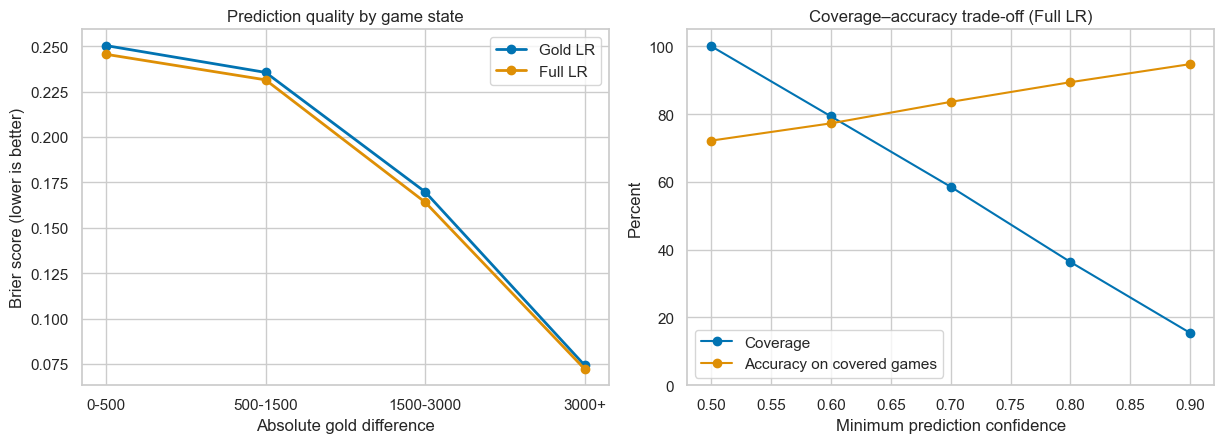

In [15]:
selected_prob = probabilities[selected_model]
selected_pred = (selected_prob >= 0.5).astype(int)
confidence = np.maximum(selected_prob, 1 - selected_prob)
correct = selected_pred == y_array

threshold_rows = []
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    mask = confidence >= threshold
    n = int(mask.sum())
    if n:
        threshold_rows.append({
            "confidence_threshold": threshold,
            "n": n,
            "correct": int(correct[mask].sum()),
            "coverage": n / len(correct),
            "mean_model_confidence": confidence[mask].mean(),
        })

confidence_summary = add_win_rate_and_ci(pd.DataFrame(threshold_rows), successes="correct")
confidence_summary = confidence_summary.rename(columns={"win_rate": "empirical_accuracy"})
display(save_table(confidence_summary, "selective_prediction.csv"))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6))
for model in ["Gold LR", "Full LR"]:
    subset = slice_metrics[slice_metrics["model"] == model].set_index("gold_band").reindex(band_labels)
    axes[0].plot(band_labels, subset["brier"], marker="o", linewidth=2, label=model)
axes[0].set(xlabel="Absolute gold difference", ylabel="Brier score (lower is better)", title="Prediction quality by game state")
axes[0].legend()

axes[1].plot(confidence_summary["confidence_threshold"], confidence_summary["coverage"] * 100, marker="o", label="Coverage")
axes[1].plot(confidence_summary["confidence_threshold"], confidence_summary["empirical_accuracy"] * 100, marker="o", label="Accuracy on covered games")
axes[1].set(xlabel="Minimum prediction confidence", ylabel="Percent", title=f"Coverage–accuracy trade-off ({selected_model})", ylim=(0, 105))
axes[1].legend()
fig.tight_layout()
save_figure(fig, "decision_diagnostics.png")

In [16]:
error_review = holdout[["game_id", "blue_win", "gold_diff", "xp_diff", "epic_diff", "kill_diff"]].copy()
error_review["predicted_blue_win_probability"] = selected_prob
error_review["predicted_blue_win"] = selected_pred
error_review["confidence"] = confidence
error_review["correct"] = correct

high_confidence_errors = error_review[
    (error_review["confidence"] >= 0.80) & (~error_review["correct"])
].sort_values("confidence", ascending=False)

high_confidence_errors = high_confidence_errors.drop(columns=["correct"])
save_table(high_confidence_errors, "high_confidence_errors.csv")
display(high_confidence_errors.head(10))
print(f"High-confidence incorrect predictions (threshold 0.80): {len(high_confidence_errors):,}")

,game_id,blue_win,gold_diff,xp_diff,epic_diff,kill_diff,predicted_blue_win_probability,predicted_blue_win,confidence
4454,4499239181,1,-5976,-4619,0,-10,0.0215,0,0.9785
9608,4517814495,0,6744,5355,0,11,0.9722,1,0.9722
9112,4518384119,1,-4552,-4208,-1,-8,0.0412,0,0.9588
1194,4448427323,0,4941,4702,0,12,0.9574,1,0.9574
2580,4519053131,0,4627,4784,0,8,0.9553,1,0.9553
4100,4419367000,1,-4903,-3146,-1,-13,0.0470,0,0.9530
7724,4525380642,0,4646,3861,1,8,0.9502,1,0.9502
3343,4479706373,1,-4738,-2857,-2,-4,0.0499,0,0.9501
6869,4504999388,1,-4907,-2874,-1,-6,0.0501,0,0.9499
376,4468741090,0,3386,2410,0,5,0.9311,1,0.9311


High-confidence incorrect predictions (threshold 0.80): 95


## 9. 结果汇总与应用边界

以下关键数字由本次运行自动提取，避免在 Notebook 中手工写死结论或使用过期输出。

In [17]:
def metric_value(model, metric):
    return float(holdout_metrics.loc[holdout_metrics["model"] == model, metric].iloc[0])


close_slice = slice_metrics[slice_metrics["gold_band"] == band_labels[0]].set_index("model")
near_objective = objective_summary[objective_summary["gold_band"] == band_labels[0]].set_index("objective_state")
confidence_80 = confidence_summary.loc[confidence_summary["confidence_threshold"] == 0.80].iloc[0]
summary = pd.DataFrame([
    ("Matches analyzed", len(features)),
    ("Gold leader win rate: 0-500", economy_summary.iloc[0]["win_rate"]),
    ("Gold leader win rate: 3000+", economy_summary.iloc[-1]["win_rate"]),
    ("Near-even gold, epic trailing: leader win rate", near_objective.loc["Trailing", "win_rate"]),
    ("Near-even gold, epic leading: leader win rate", near_objective.loc["Leading", "win_rate"]),
    ("Gold LR holdout AUC", metric_value("Gold LR", "auc")),
    ("Full LR holdout AUC", metric_value("Full LR", "auc")),
    ("Full LR holdout accuracy", metric_value("Full LR", "accuracy")),
    ("Full LR vs Gold LR Brier reduction", float(comparison.loc[comparison["metric"] == "Brier reduction", "estimate"].iloc[0])),
    ("Near-even Gold LR Brier", close_slice.loc["Gold LR", "brier"]),
    ("Near-even Full LR Brier", close_slice.loc["Full LR", "brier"]),
    ("Selected model", selected_model),
    ("Confidence >= 0.80 coverage", confidence_80["coverage"]),
    ("Confidence >= 0.80 empirical accuracy", confidence_80["empirical_accuracy"]),
], columns=["metric", "value"])
display(save_table(summary, "key_results.csv"))

,metric,value
0,Matches analyzed,9879
1,Gold leader win rate: 0-500,0.5256
2,Gold leader win rate: 3000+,0.9077
3,"Near-even gold, epic trailing: leader win rate",0.4388
4,"Near-even gold, epic leading: leader win rate",0.6010
5,Gold LR holdout AUC,0.8010
6,Full LR holdout AUC,0.8108
7,Full LR holdout accuracy,0.7219
8,Full LR vs Gold LR Brier reduction,0.0043
9,Near-even Gold LR Brier,0.2503


### 应用建议

- **战局诊断：** 按经济优势程度提供观测胜率及不确定性，帮助分析师、教练或赛后复盘解读前期优势是否稳固。
- **竞争态势解读：** 在经济近似的情境内部检查地图资源状态，标记经济领先但资源控制不足的对局供进一步复盘。
- **胜率展示：** 以 log loss、Brier score 和可靠性图共同评估候选概率模型，根据覆盖率与正确率权衡展示置信度；将高置信错误加入复核清单。

### 限制与后续验证

- 样本来自特定高段位排位赛，仅有一个 10 分钟截面；未知比赛版本、阵容、玩家实力等因素，不能泛化到其他段位、版本或游戏模式。
- 随机划分检验的是同一数据分布中的样本外表现，并非跨版本、时间滚动或真实线上验证。若得到比赛时间戳，应按时间或版本划分评估。
- 战局分层及预测不能作为操作因果建议。若要估计拿龙、拿先锋等决策的影响，应取得操作发生时点、操作前状态和之后结果，并设计符合时间顺序的识别策略。